# 03 · Evaluation: how far the numbers can be trusted

**Forecasting Antibiotic Resistance with AI** · Final Year Project · Hamza Afzal (models), Muhammad Ali Mirza (data and evolution), Suleman Saleh (platform)

Notebooks 01 and 02 train the served models. This one gathers the checks behind every number in the report, from the runs saved in `experiments/results/` (each made with `experiments/run.py` and a config in `experiments/configs/`):

1. Genomes seen in training vs genomes never seen (why the July 0.93 was misleading)
2. Repeat runs with different splits (seeds)
3. Significance tests between models
4. Related bacteria held out (lineage split)
5. Bacteria collected after the training years (temporal test)
6. Calibration of the served forecaster

Run time: about 1 minute (no training).

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import Markdown, Image, display

ROOT = os.path.abspath('..')
RES = os.path.join(ROOT, 'experiments', 'results')
sys.path.insert(0, os.path.join(ROOT, 'experiments'))

def metrics_of(run_id):
    return json.load(open(os.path.join(RES, run_id, 'metrics.json')))

## 1. Seen vs never-seen genomes

`experiments/evaluate_shipped.py` re-tests each model the website serves (and the July models it replaced) on genomes it trained on and on genomes it never saw. The July forecaster scored 0.94 on its own training genomes but **0.64 on new ones**: its published 0.93 came from a random row split that put the same genomes in training and test. Every current number uses a split by genome.

In [2]:
shipped = json.load(open(os.path.join(RES, 'shipped_eval.json')))
names = {'lightgbm_previous': 'July forecaster (retired)', 'lightgbm': 'Forecaster now served',
         'kmer_previous': 'July k-mer RandomForest (retired)', 'kmer': 'Genome k-mer model now served'}
rows = []
for key in ['lightgbm_previous', 'lightgbm', 'kmer_previous', 'kmer']:
    for r in shipped[key]['results'][:2]:
        rows.append({'model': names[key], 'tested on': r['subset'], 'rows': r['rows'],
                     'AUC': r['auc_roc'], '95% CI': f"[{r['auc_ci'][0]:.3f}, {r['auc_ci'][1]:.3f}]"})
pd.DataFrame(rows)

,model,tested on,rows,AUC,95% CI
0,July forecaster (retired),Genomes it trained on,24983,0.9408,"[0.933, 0.948]"
1,July forecaster (retired),Genomes it never saw,1514981,0.6437,"[0.642, 0.645]"
2,Forecaster now served,"Genomes it trained on (sample of 20,000)",356489,0.7639,"[0.760, 0.767]"
3,Forecaster now served,Genomes it never saw,1569432,0.7617,"[0.760, 0.764]"
4,July k-mer RandomForest (retired),Genomes it trained on,6002,0.9806,"[0.974, 0.986]"
5,July k-mer RandomForest (retired),Genomes it never saw,49881,0.6949,"[0.678, 0.714]"
6,Genome k-mer model now served,"Genomes it trained on (lab labels, sample of 5...",44604,0.9595,"[0.957, 0.962]"
7,Genome k-mer model now served,Genomes it never saw (lab labels),40356,0.9345,"[0.931, 0.939]"


## 2. Seeds: does a result depend on how the genomes were split?

Each model was trained three times with different random splits (seeds 42, 1 and 2). The spread (standard deviation) is the split-to-split variation a single run's confidence interval does not show.

In [3]:
import report
display(Markdown(report.seed_table()))

| Run | Seeds | AUC mean ± sd | Lab AUC mean ± sd | AUPRC mean ± sd | VME mean ± sd | ME mean ± sd |
|---|---|---|---|---|---|---|
| `A10_monotonic_mic_v7` | 3 | 0.7845 ± 0.0005 | 0.9178 ± 0.0017 | 0.6114 ± 0.0010 | 0.148 ± 0.006 | 0.473 ± 0.008 |
| `A2_oof_grouped_v7` | 3 | 0.7849 ± 0.0005 | 0.9206 ± 0.0018 | 0.6123 ± 0.0009 | 0.145 ± 0.001 | 0.477 ± 0.000 |
| `A6_lab_only_v7` | 3 | 0.9214 ± 0.0012 | 0.9214 ± 0.0012 | 0.8812 ± 0.0016 | 0.122 ± 0.002 | 0.237 ± 0.004 |
| `A6b_lab_only_no_mic_v7` | 3 | 0.8376 ± 0.0024 | 0.8376 ± 0.0024 | 0.7480 ± 0.0034 | 0.162 ± 0.001 | 0.361 ± 0.002 |
| `A_ablation_drug_only_v7` | 3 | 0.6569 ± 0.0004 | 0.6078 ± 0.0008 | 0.4240 ± 0.0009 | 0.180 ± 0.065 | 0.640 ± 0.091 |
| `B6L_genes_v7` | 3 | 0.9820 ± 0.0006 | 0.9789 ± 0.0004 | 0.9773 ± 0.0005 | 0.076 ± 0.003 | 0.057 ± 0.001 |

## 3. Significance: is model A really better than model B?

`experiments/compare.py` compares two models on the test rows they share: DeLong's test for the AUC difference, McNemar's test for the calls at each model's threshold, and a paired bootstrap that resamples whole genomes (each genome has many rows, so it is the interval to quote when the two disagree). "(lab)" = lab-confirmed rows only.

In [4]:
sig = json.load(open(os.path.join(RES, 'significance.json')))
fmt_p = lambda p: '< 0.0001' if p < 1e-4 else f'{p:.4f}'
pd.DataFrame([{'A': r['a'] + (' (lab)' if r['lab_only'] else ''), 'B': r['b'], 'rows': r['rows'],
               'AUC A': round(r['delong']['auc_a'], 4), 'AUC B': round(r['delong']['auc_b'], 4),
               'difference': round(r['delong']['diff'], 4), 'DeLong p': fmt_p(r['delong']['p']),
               'genome bootstrap 95% CI': f"[{r['bootstrap']['ci'][0]:+.4f}, {r['bootstrap']['ci'][1]:+.4f}]",
               'McNemar p': fmt_p(r['mcnemar']['p'])} for r in sig])

,A,B,rows,AUC A,AUC B,difference,DeLong p,genome bootstrap 95% CI,McNemar p
0,B6L_genes_v6 (lab),B4L_kmer4_lgbm_v6,40356,0.9790,0.9345,0.0445,< 0.0001,"[+0.0413, +0.0476]",< 0.0001
1,B7L_genes_kmers_v6 (lab),B6L_genes_v6,40356,0.9809,0.9790,0.0019,< 0.0001,"[+0.0012, +0.0026]",< 0.0001
2,B6L_genes_v6 (lab),B6L_base_taxonomy_v6,40356,0.9790,0.8487,0.1303,< 0.0001,"[+0.1236, +0.1360]",< 0.0001
3,B6L_genes_v6 (lab),B6L_base_drug_v6,40356,0.9790,0.7147,0.2643,< 0.0001,"[+0.2589, +0.2698]",< 0.0001
4,A2_oof_grouped_v7,A_ablation_drug_only_v7,1569432,0.7850,0.6572,0.1277,< 0.0001,"[+0.1260, +0.1296]",< 0.0001
5,A6_lab_only_v7,A6b_lab_only_no_mic_v7,129992,0.9227,0.8400,0.0827,< 0.0001,"[+0.0797, +0.0857]",< 0.0001
6,A10_monotonic_mic_v7,A2_oof_grouped_v7,1569432,0.7846,0.7850,-0.0004,< 0.0001,"[-0.0004, -0.0003]",0.1358


Reading the table: genes beat k-mers, taxonomy and the antibiotic alone; adding k-mers to genes gains only 0.002 (real but negligible). The forecaster's features beat knowing only the drug by 0.128, and the MIC adds 0.083 on lab rows. A10 vs A2 (the monotone MIC rule) differs by 0.0004 with McNemar p = 0.14: the rule costs nothing.

## 4. Lineage split: are related bacteria inflating the scores?

Two genomes can be different genomes yet near-identical relatives. `experiments/genome/lineage.py` clusters the 24,926 genomes by 6-mer distance within each species; the lineage split keeps a whole cluster on one side (close = near-identical relatives, broad = about species-wide groups).

In [5]:
rows = []
for model, ids in [('Gene model (B6)', ['B6L_genes_v7', 'LL_close_genes_v7', 'LL_broad_genes_v7']),
                   ('k-mer model', ['B4L_kmer4_lgbm_v7', 'LL_close_kmer4_v7', 'LL_broad_kmer4_v7']),
                   ('Forecaster design A2', ['LT_A2_grouped_v7', 'LT_A2_close_v7', 'LT_A2_broad_v7']),
                   ('Served forecaster design D3', ['LT_D3_grouped_v7', 'LT_D3_close_v7', 'LT_D3_broad_v7'])]:
    lab = [metrics_of(i)['test_by_label_source']['lab']['auc_roc'] for i in ids]
    rows.append({'model': model, 'by genome': round(lab[0], 3), 'close lineages held out': round(lab[1], 3),
                 'broad lineages held out': round(lab[2], 3), 'largest drop': round(lab[0] - min(lab), 3)})
pd.DataFrame(rows)

,model,by genome,close lineages held out,broad lineages held out,largest drop
0,Gene model (B6),0.979,0.979,0.965,0.014
1,k-mer model,0.934,0.926,0.900,0.035
2,Forecaster design A2,0.968,0.967,0.961,0.007
3,Served forecaster design D3,0.962,0.962,0.961,0.001


## 5. Temporal test: bacteria collected after the training years

Ali added each genome's collection year from BV-BRC. The model (A6: lab rows, same features as the forecaster) is trained on genomes collected up to a cut-off year and tested on later ones, which is the real forecasting question. The grouped twin uses the same genomes with a random split.

In [6]:
rows = []
for run_id, label in [('T0_grouped_withyear_v7', 'random split (same genomes)'), ('T1_temporal_2012_v7', 'trained up to 2012'),
                      ('T1_temporal_2014_v7', 'trained up to 2014'), ('T1_temporal_2015_v7', 'trained up to 2015')]:
    t = metrics_of(run_id)['test']
    rows.append({'test': label, 'test rows': t['n'], 'AUC': round(t['auc_roc'], 3),
                 '95% CI': f"[{t['auc_roc_ci'][0]:.3f}, {t['auc_roc_ci'][1]:.3f}]",
                 'missed resistant (VME)': f"{t['very_major_error']:.1%}"})
pd.DataFrame(rows)

,test,test rows,AUC,95% CI,missed resistant (VME)
0,random split (same genomes),114241,0.928,"[0.925, 0.931]",11.2%
1,trained up to 2012,318713,0.878,"[0.875, 0.880]",19.1%
2,trained up to 2014,226045,0.857,"[0.855, 0.860]",23.0%
3,trained up to 2015,169597,0.857,"[0.854, 0.860]",20.2%


In [7]:
# AUC by collection year of the test genomes, trained up to 2014
from sklearn.metrics import roc_auc_score
meta = pd.read_csv(os.path.join(ROOT, 'Data', 'genome_meta', 'genome_meta.csv'),
                   dtype={'genome_id': str}, usecols=['genome_id', 'year']).dropna()
year = dict(zip(meta.genome_id, meta.year.astype(int)))
p = pd.read_csv(os.path.join(RES, 'T1_temporal_2014_v7', 'predictions.csv'), dtype={'genome_id': str})
p['year'] = p.genome_id.map(year)
by_year = [{'year': int(y), 'test rows': len(g), 'AUC': round(roc_auc_score(g.y_true, g.y_score), 3)}
           for y, g in p.groupby('year') if len(g) >= 1000 and g.y_true.nunique() == 2]
pd.DataFrame(by_year).set_index('year').T

year,2015,2016,2017,2018,2019,2020,2021,2022
test rows,56448.000,39619.000,56641.00,45818.00,10375.000,7948.000,5656.000,3540.000
AUC,0.868,0.876,0.82,0.82,0.957,0.823,0.909,0.966


The loss is not a steady decay with time: it sits in 2017 to 2018 and inside particular genera (*Shigella*, *Neisseria*, *Salmonella*) where resistance spread after the training years. Details: `experiments/TEMPORAL_RESULTS.md`.

## 6. Calibration of the served forecaster

Isotonic calibration, fitted on validation genomes, brings the predicted probabilities onto the diagonal (Brier score 0.193 → 0.160). Plot made by `experiments/calibration_plot.py`.

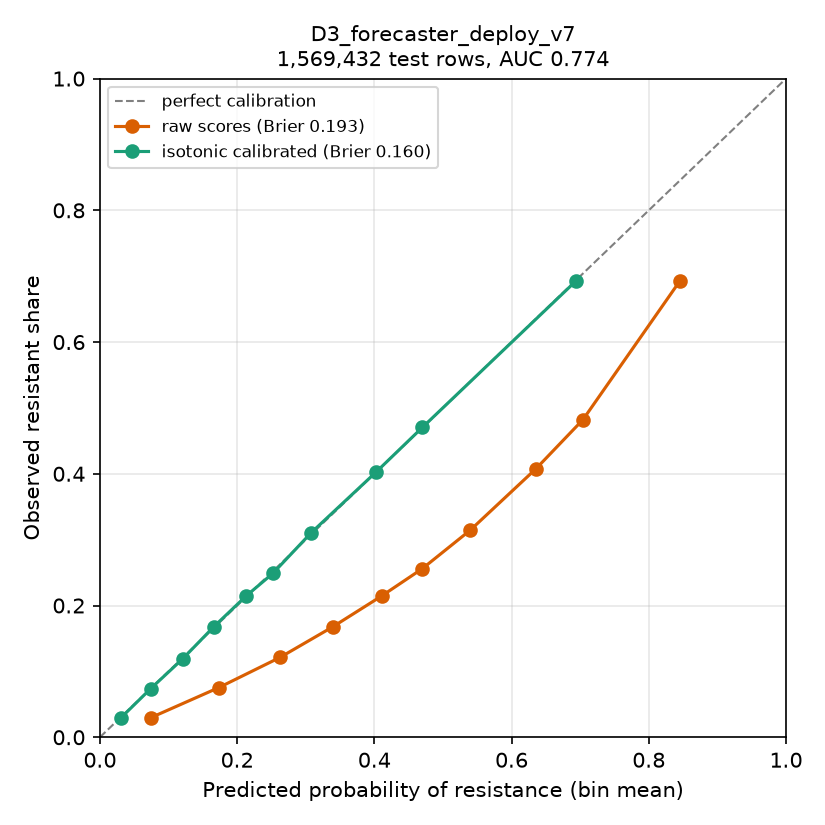

In [8]:
display(Image(filename=os.path.join(RES, 'figures', 'calibration_D3_forecaster_deploy_v7.png'), width=480))